# Decision Tree — classification PCG (normal / abnormal)
**Pipeline :** mêmes données/split que le SVM → arbre de décision → seuil sur validation → évaluation test + importance des features

> **Section 7 et suivantes** : version alignée sur le notebook `SVM.ipynb` — mêmes features
> segmentées (46 valeurs via `preprocess.py`), mêmes 3 plis, `GridSearchCV`, sauvegarde du
> meilleur arbre et suivi MLflow, pour comparer SVM et arbre de décision sur un pied d'égalité.


## Decision Tree

La partie ci-dessus utilise `ourdataset/processed/dataset_2000hz.npz` (split train/val/test
du projet) et un seuil réglé sur la validation : impossible de comparer directement avec le
SVM, qui est évalué sur les 3 plis `train_kfoldK` / `test_kfoldK`.

Cette section applique donc **exactement le même protocole que `SVM.ipynb`** :

- 46 features par segment de 5 s calculées par `preprocess.py` (cache partagé
  `models/tp3_features_segments.npz`, créé par le notebook SVM) ;
- mêmes 3 plis (`KFold(shuffle=True, random_state=10)` sur les fichiers triés) ;
- `DecisionTreeClassifier(class_weight="balanced")` réglé par `GridSearchCV`
  (`max_depth`, `min_samples_leaf`, `criterion`), validation croisée **groupée par
  enregistrement** (`GroupKFold`) pour éviter la fuite entre segments d'un même WAV ;
- réentraînement sur toutes les données, **sauvegarde** dans `audio_engine/models/best_tree.joblib`
  et **enregistrement MLflow** dans l'expérience `tp3_audio_engine`.

In [1]:
import json
import sys
from collections import defaultdict
from datetime import datetime
from pathlib import Path
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)

# Dossier du notebook = audio_engine/ ; données dans ../ourdataset/train
DATA_DIR = next((p / "ourdataset" / "train" for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "ourdataset" / "train").is_dir()), None)
assert DATA_DIR is not None, f"ourdataset/train introuvable depuis {Path.cwd()}"
DATA_DIR = DATA_DIR.resolve()
AUDIO_ENGINE_DIR = DATA_DIR.parent.parent / "audio_engine"
sys.path.insert(0, str(AUDIO_ENGINE_DIR))
from preprocess import AudioError, Preprocessor

MODEL_DIR = AUDIO_ENGINE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
PLOT_DIR = MODEL_DIR / "plots"
PLOT_DIR.mkdir(exist_ok=True)
CACHE_PATH = MODEL_DIR / "tp3_features_segments.npz"

# sr=2000 Hz, passe-bande 25-400 Hz, segments de 5 s avec 50 % de recouvrement
pre = Preprocessor()
print(f"Features par segment : {len(pre.names)}")

Features par segment : 46


In [2]:
def load_or_extract_features():
    '''46 features par segment de 5 s (cache partagé avec SVM.ipynb).'''
    if CACHE_PATH.exists():
        data = np.load(CACHE_PATH, allow_pickle=True)
        print(f"Cache réutilisé : {CACHE_PATH.name} ({len(data['X'])} segments)")
        return data["X"], data["files"], data["y"]

    # même calcul que SVM.ipynb : utile si le notebook SVM n'a pas encore été lancé
    recordings = ([(f, 0) for f in sorted((DATA_DIR / "normal").glob("*.wav"))] +
                  [(f, 1) for f in sorted((DATA_DIR / "abnormal").glob("*.wav"))])
    X_list, files_list, labels_list = [], [], []
    for i, (file, label) in enumerate(recordings, start=1):
        try:
            signal = pre.load_clean(file.read_bytes())
        except AudioError as error:
            print(f"  ignoré {file.name}: {error}")
            continue
        segments = pre.segment(signal)
        X_list.append(pre.batch(segments, "features"))
        files_list += [file.name] * len(segments)
        labels_list += [label] * len(segments)
        if i % 500 == 0:
            print(f"  {i}/{len(recordings)} fichiers, {sum(map(len, X_list))} segments")

    X_all = np.vstack(X_list).astype(np.float32)
    files_all = np.array(files_list)
    y_all = np.array(labels_list, dtype=np.int8)
    np.savez_compressed(CACHE_PATH, X=X_all, files=files_all, y=y_all,
                        feat_names=np.array(pre.names))
    print(f"Cache écrit : {CACHE_PATH}")
    return X_all, files_all, y_all


X_all, files_all, y_all = load_or_extract_features()

# --- mêmes plis que SVM.ipynb (fichiers triés + même graine)
CROSS_NUMBER, SEED = 3, 10
kf = KFold(n_splits=CROSS_NUMBER, shuffle=True, random_state=SEED)
normal_paths = sorted((DATA_DIR / "normal").glob("*.wav"))
abnormal_paths = sorted((DATA_DIR / "abnormal").glob("*.wav"))

# clés "classe/nom.wav" : 2 noms existent à la fois dans normal/ et abnormal/
keys_all = np.array([f"{label}/{name}" for label, name in zip(y_all, files_all)])

fold_splits = []
for (tr_n, te_n), (tr_a, te_a) in zip(kf.split(normal_paths), kf.split(abnormal_paths)):
    fold_splits.append((
        {f"0/{normal_paths[i].name}" for i in tr_n} | {f"1/{abnormal_paths[i].name}" for i in tr_a},
        {f"0/{normal_paths[i].name}" for i in te_n} | {f"1/{abnormal_paths[i].name}" for i in te_a},
    ))

print(f"{len(y_all)} segments, {len(np.unique(files_all))} enregistrements")
print(f"normal : {(y_all == 0).sum()} segments | abnormal : {(y_all == 1).sum()} segments")

Cache réutilisé : tp3_features_segments.npz (24990 segments)
24990 segments, 3779 enregistrements
normal : 18886 segments | abnormal : 6104 segments


###  Recherche d'hyperparamètres et évaluation sur les 3 plis

In [3]:
PARAM_GRID = {
    "max_depth": [4, 6, 8, 12],
    "min_samples_leaf": [1, 5, 20],
    "criterion": ["gini", "entropy"],
}

fold_rows = []
fold_outputs = []                         # probabilités par pli : ROC et matrice de confusion
param_scores = defaultdict(list)          # hyperparamètres -> scores CV des 3 plis

for k, (train_keys, test_keys) in enumerate(fold_splits, start=1):
    train_mask = np.isin(keys_all, list(train_keys))
    test_mask = np.isin(keys_all, list(test_keys))

    search = GridSearchCV(
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        PARAM_GRID,
        cv=GroupKFold(n_splits=CROSS_NUMBER),
        scoring="balanced_accuracy",
        n_jobs=-1,
    )
    search.fit(X_all[train_mask], y_all[train_mask], groups=files_all[train_mask])

    for params, score in zip(search.cv_results_["params"], search.cv_results_["mean_test_score"]):
        param_scores[tuple(sorted(params.items()))].append(score)

    proba = search.predict_proba(X_all[test_mask])[:, 1]
    y_pred = (proba >= 0.5).astype(int)
    y_test = y_all[test_mask]
    fold_outputs.append({"fold": k, "y_true": y_test, "proba": proba, "y_pred": y_pred})

    row = {
        "fold": k,
        "best_params": search.best_params_,
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "macro_precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba),
    }
    fold_rows.append(row)
    print(f"pli {k}: {search.best_params_}")
    print(f"        exactitude={row['accuracy']:.3f}  BA={row['balanced_accuracy']:.3f}  "
          f"macro précision={row['macro_precision']:.3f}  macro F1={row['macro_f1']:.3f}  "
          f"AUC={row['roc_auc']:.3f}")

metrics = ("accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "roc_auc")
improved_tree = {m: float(np.mean([row[m] for row in fold_rows])) for m in metrics}

# Meilleurs hyperparamètres = meilleur score CV moyen sur les 3 plis
BEST_PARAMS_TREE = dict(max(param_scores, key=lambda p: np.mean(param_scores[p])))
CV_SCORE_TREE = float(np.mean(param_scores[max(param_scores, key=lambda p: np.mean(param_scores[p]))]))

# --- comparaison avec le SVM sauvegardé (si le notebook SVM a déjà tourné)
svm_meta_path = MODEL_DIR / "best_svm_meta.json"
svm_metrics = None
if svm_meta_path.exists():
    svm_metrics = json.loads(svm_meta_path.read_text(encoding="utf-8"))["mean_metrics"]

print("\n" + "-" * 62)
print(f"Arbre de décision (46 features segmentées, 3 plis) : macro précision = {improved_tree['macro_precision']:.3f}")
print(f"                                                     exactitude      = {improved_tree['accuracy']:.3f}")
print(f"                                                     BA              = {improved_tree['balanced_accuracy']:.3f}")
print(f"                                                     macro F1        = {improved_tree['macro_f1']:.3f}")
print(f"                                                     AUC             = {improved_tree['roc_auc']:.3f}")
print(f"Meilleurs hyperparamètres : {BEST_PARAMS_TREE} (BA CV = {CV_SCORE_TREE:.3f})")

pli 1: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 5}
        exactitude=0.798  BA=0.831  macro précision=0.753  macro F1=0.766  AUC=0.895
pli 2: {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 20}
        exactitude=0.808  BA=0.827  macro précision=0.761  macro F1=0.776  AUC=0.887
pli 3: {'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 1}
        exactitude=0.828  BA=0.839  macro précision=0.776  macro F1=0.794  AUC=0.865

--------------------------------------------------------------
Arbre de décision (46 features segmentées, 3 plis) : macro précision = 0.763
                                                     exactitude      = 0.811
                                                     BA              = 0.832
                                                     macro F1        = 0.779
                                                     AUC             = 0.883
Meilleurs hyperparamètres : {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 1}

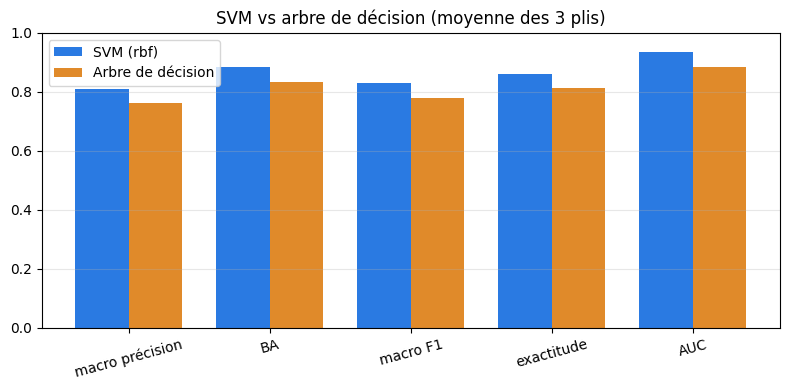

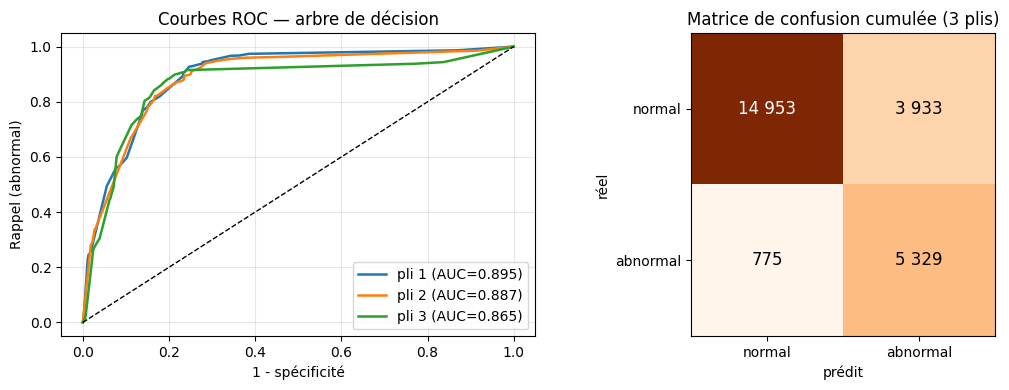

In [4]:
# --- Figure 1 : SVM vs arbre de décision
fig, ax = plt.subplots(figsize=(8, 4))
labels = ["macro précision", "BA", "macro F1", "exactitude", "AUC"]
keys = ["macro_precision", "balanced_accuracy", "macro_f1", "accuracy", "roc_auc"]
x = np.arange(len(labels))
width = 0.38

if svm_metrics is not None:
    ax.bar(x - width / 2, [svm_metrics[k] for k in keys], width, label="SVM (rbf)", color="#2a7ae2")
ax.bar(x + width / 2, [improved_tree[k] for k in keys], width, label="Arbre de décision", color="#e08a2a")
ax.set_xticks(x, labels, rotation=15)
ax.set_ylim(0, 1)
ax.set_title("SVM vs arbre de décision (moyenne des 3 plis)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
TREE_COMPARISON_PLOT = PLOT_DIR / "tp3_tree_vs_svm.png"
fig.savefig(TREE_COMPARISON_PLOT, dpi=150)
plt.show()

# --- Figure 2 : ROC et matrice de confusion cumulée
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for out in fold_outputs:
    fpr, tpr, _ = roc_curve(out["y_true"], out["proba"])
    axes[0].plot(fpr, tpr, lw=1.8, label=f"pli {out['fold']} (AUC={roc_auc_score(out['y_true'], out['proba']):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("1 - spécificité")
axes[0].set_ylabel("Rappel (abnormal)")
axes[0].set_title("Courbes ROC — arbre de décision")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

cm_total = sum(confusion_matrix(out["y_true"], out["y_pred"], labels=[0, 1]) for out in fold_outputs)
axes[1].imshow(cm_total, cmap="Oranges")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm_total[i, j]:,}".replace(",", " "), ha="center", va="center",
                     color="white" if cm_total[i, j] > cm_total.max() / 2 else "black", fontsize=12)
axes[1].set_xticks([0, 1], ["normal", "abnormal"])
axes[1].set_yticks([0, 1], ["normal", "abnormal"])
axes[1].set_xlabel("prédit")
axes[1].set_ylabel("réel")
axes[1].set_title("Matrice de confusion cumulée (3 plis)")

fig.tight_layout()
TREE_ROC_PLOT = PLOT_DIR / "tp3_tree_roc_confusion.png"
fig.savefig(TREE_ROC_PLOT, dpi=150)
plt.show()

###  Courbes d'apprentissage par pli

M?me lecture que pour le SVM : score `balanced_accuracy` et perte (`1 - score`)
selon la taille du jeu d'entra?nement, avec une validation `GroupKFold(3)` group?e
par enregistrement. Les figures/CSV et les m?triques `foldK_lc_*` sont envoy?s ? MLflow.


In [5]:
# --- Courbes d'apprentissage par pli (train vs validation CV group?e) ---
from fold_utils import (compute_learning_curve, plot_all_folds_learning_curves,
                        plot_learning_curve, save_learning_curve_csv)

learning_curves, lc_histories, lc_artifacts = [], [], {}
tree_for_curve = DecisionTreeClassifier(class_weight="balanced", random_state=42,
                                        **BEST_PARAMS_TREE)

for k, (train_keys, test_keys) in enumerate(fold_splits, start=1):
    train_mask = np.isin(keys_all, list(train_keys))
    curve = compute_learning_curve(
        tree_for_curve, X_all[train_mask], y_all[train_mask], groups=files_all[train_mask],
        train_sizes=np.linspace(0.1, 1.0, 5), cv_splits=CROSS_NUMBER,
        scoring="balanced_accuracy", n_jobs=-1, random_state=SEED,
    )
    curve["fold"] = k
    learning_curves.append(curve)

    plot_path = plot_learning_curve(curve, k, PLOT_DIR, "tree", color="#e08a2a")
    csv_path = save_learning_curve_csv(curve, MODEL_DIR / f"tree_fold{k}_learning_curve.csv")
    lc_artifacts[str(plot_path)] = "plots"
    lc_artifacts[str(csv_path)] = "curves"
    lc_histories.append({
        "fold": k,
        "steps": curve["train_sizes"],
        "metrics": {
            "lc_train_score": curve["train_score_mean"],
            "lc_val_score": curve["val_score_mean"],
            "lc_train_loss": curve["train_loss_mean"],
            "lc_val_loss": curve["val_loss_mean"],
        },
    })
    print(f"pli {k} : {curve['train_sizes']} segments | "
          f"score validation final = {curve['val_score_mean'][-1]:.3f}")

LC_ALL_PLOT = plot_all_folds_learning_curves(learning_curves, PLOT_DIR, "tree")
lc_artifacts[str(LC_ALL_PLOT)] = "plots"
print("Courbes d'apprentissage :", LC_ALL_PLOT)


pli 1 : [1122, 3647, 6173, 8698, 11224] segments | score validation final = 0.817
pli 2 : [1121, 3643, 6165, 8687, 11210] segments | score validation final = 0.835
pli 3 : [1088, 3537, 5987, 8436, 10886] segments | score validation final = 0.818
Courbes d'apprentissage : C:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\plots\tree_learning_curves_all_folds.png


## 8. Réentraînement final et sauvegarde du meilleur arbre

In [6]:
# --- Réentraînement sur TOUTES les données avec les meilleurs hyperparamètres
best_tree = DecisionTreeClassifier(class_weight="balanced", random_state=42, **BEST_PARAMS_TREE)
best_tree.fit(X_all, y_all)

TREE_MODEL_PATH = MODEL_DIR / "best_tree.joblib"
TREE_META_PATH = MODEL_DIR / "best_tree_meta.json"
joblib.dump(best_tree, TREE_MODEL_PATH, compress=3)

importance = sorted(zip(pre.names, best_tree.feature_importances_), key=lambda item: item[1], reverse=True)

meta_tree = {
    "model": "DecisionTreeClassifier",
    "file": str(TREE_MODEL_PATH),
    "created_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "best_params": BEST_PARAMS_TREE,
    "cv": f"GridSearchCV + GroupKFold({CROSS_NUMBER}) groupé par enregistrement",
    "cv_balanced_accuracy": CV_SCORE_TREE,
    "fold_metrics": fold_rows,
    "mean_metrics": improved_tree,
    "svm_reference": svm_metrics,
    "tree": {"depth": int(best_tree.get_depth()), "n_leaves": int(best_tree.get_n_leaves())},
    "top_features": [{"name": name, "importance": float(value)} for name, value in importance[:10]],
    "features": {
        "source": "preprocess.Preprocessor",
        "n_features": len(pre.names),
        "names": list(pre.names),
        "sample_rate": pre.sr,
        "segment_sec": pre.seg_len / pre.sr,
        "hop_sec": pre.hop_len / pre.sr,
    },
    "labels": {"0": "normal", "1": "abnormal"},
    "n_segments": int(len(y_all)),
    "n_recordings": int(len(np.unique(files_all))),
    "class_counts": {"normal": int((y_all == 0).sum()), "abnormal": int((y_all == 1).sum())},
    "versions": {"sklearn": __import__("sklearn").__version__},
    "usage": "clf = joblib.load('models/best_tree.joblib'); "
             "sig = pre.load_clean(open(wav, 'rb').read()); "
             "X = pre.batch(pre.segment(sig), 'features'); clf.predict(X)",
}
TREE_META_PATH.write_text(json.dumps(meta_tree, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Arbre entraîné sur {len(y_all)} segments ({len(np.unique(files_all))} enregistrements)")
print(f"profondeur={best_tree.get_depth()}  feuilles={best_tree.get_n_leaves()}")
print(f"Modèle sauvegardé : {TREE_MODEL_PATH} ({TREE_MODEL_PATH.stat().st_size / 1e6:.2f} Mo)")
print(f"Métadonnées       : {TREE_META_PATH}")

Arbre entraîné sur 24990 segments (3779 enregistrements)
profondeur=6  feuilles=58
Modèle sauvegardé : C:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\best_tree.joblib (0.01 Mo)
Métadonnées       : C:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\best_tree_meta.json


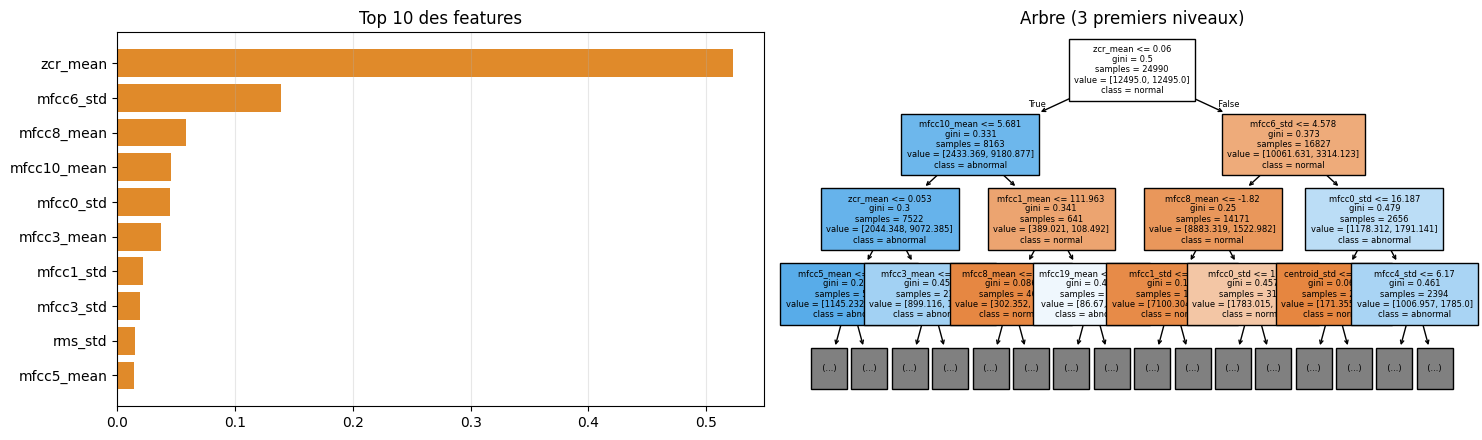

Au niveau enregistrement (1260 WAV du pli 3, segments agrégés) : exactitude=0.790  BA=0.837  AUC=0.906
  normal   :  975 WAV, rappel=0.248
  abnormal :  285 WAV, rappel=0.923
       101_1305030823364_B.wav : attendu=normal   prédit=normal   proba=0.37
       112_1306243000964_A.wav : attendu=abnormal prédit=normal   proba=0.36


In [7]:
# --- Figure 3 : interprétabilité du modèle sauvegardé (top 10 features + 3 niveaux de l'arbre)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

top = importance[:10]
axes[0].barh([name for name, _ in top][::-1], [value for _, value in top][::-1], color="#e08a2a")
axes[0].set_title("Top 10 des features")
axes[0].grid(axis="x", alpha=0.3)

plot_tree(best_tree, max_depth=3, feature_names=list(pre.names),
          class_names=["normal", "abnormal"], filled=True, fontsize=6, ax=axes[1])
axes[1].set_title("Arbre (3 premiers niveaux)")

fig.tight_layout()
TREE_PLOT = PLOT_DIR / "tp3_tree_interpretation.png"
fig.savefig(TREE_PLOT, dpi=150)
plt.show()

# --- Vérification : décision au niveau enregistrement sur tout le pli 3
# Chaque WAV = plusieurs segments ; on agrège en moyennant la probabilité "abnormal".
loaded_tree = joblib.load(TREE_MODEL_PATH)


def aggregate_to_recordings(scores, keys):
    """Moyenne des scores de segments par enregistrement -> (labels, scores)."""
    per_key = {}
    for score, key in zip(scores, keys):
        per_key.setdefault(key, []).append(score)
    items = sorted(per_key)
    return np.array([int(key[0]) for key in items]), np.array([np.mean(per_key[k]) for k in items])


test_mask = np.isin(keys_all, list(fold_splits[-1][1]))
y_rec, score_rec = aggregate_to_recordings(loaded_tree.predict_proba(X_all[test_mask])[:, 1],
                                           keys_all[test_mask])
pred_rec = (score_rec >= 0.5).astype(int)

print(f"Au niveau enregistrement ({len(y_rec)} WAV du pli 3, segments agrégés) : "
      f"exactitude={accuracy_score(y_rec, pred_rec):.3f}  "
      f"BA={balanced_accuracy_score(y_rec, pred_rec):.3f}  "
      f"AUC={roc_auc_score(y_rec, score_rec):.3f}")
for name, label in (("normal", 0), ("abnormal", 1)):
    sel = y_rec == label
    print(f"  {name:<8} : {sel.sum():>4} WAV, rappel={pred_rec[sel].mean():.3f}")

# --- Exemple d'utilisation sur deux fichiers (le premier lisible de chaque classe)
for nametype in ("normal", "abnormal"):
    for demo_file in sorted((DATA_DIR / nametype).glob("*.wav")):
        try:
            signal = pre.load_clean(demo_file.read_bytes())
        except AudioError:
            continue
        proba = float(loaded_tree.predict_proba(pre.batch(pre.segment(signal), "features"))[:, 1].mean())
        print(f"  {demo_file.name:>28} : attendu={nametype:<8} "
              f"prédit={'abnormal' if proba >= 0.5 else 'normal':<8} proba={proba:.2f}")
        break


### Lecture des résultats

- **Au niveau segment** (métriques du tableau ci-dessus), l'arbre atteint BA ≈ 0,83 pour un AUC ≈ 0,88 :
  c'est le niveau auquel il est entraîné et comparé au SVM.
- **Au niveau enregistrement** (probabilités moyennées sur les segments du WAV), la BA monte à ≈ 0,84
  car les erreurs ponctuelles se compensent sur plusieurs segments.
- `class_weight="balanced"` + seuil 0,5 privilégie le rappel « abnormal » (≈ 0,92) au détriment du
  rappel « normal » (≈ 0,25) : c'est le compromis attendu pour un dépistage, mais le seuil peut être
  déplacé selon le coût relatif des faux positifs et des faux négatifs
  (cf. `best_tree_meta.json` pour rejouer le réglage).

## Suivi MLflow

Même expérience que le SVM et le CNN (`tp3_audio_engine`) : les runs `svm_rbf_segments`,
`decision_tree_gridsearch` et `cnn_mel_segments` sont donc comparables directement dans
l'interface MLflow, et les trois modèles sont servis ensemble par `audio_engine/registry.py`
(endpoint `/predict_all` de l'interface web).
Le run contient les hyperparamètres, les métriques par pli et moyennes, les figures
(comparaison SVM/arbre, ROC, matrice de confusion, interprétation), le fichier
`best_tree.joblib`, ses métadonnées et le modèle sérialisé par `mlflow.sklearn`.

In [8]:
import sys
sys.path.insert(0, str(AUDIO_ENGINE_DIR))
from mlflow_utils import log_classifier_run

mlflow_params = {
    "model": "DecisionTree",
    "criterion": BEST_PARAMS_TREE["criterion"],
    "max_depth": BEST_PARAMS_TREE["max_depth"],
    "min_samples_leaf": BEST_PARAMS_TREE["min_samples_leaf"],
    "class_weight": "balanced",
    "random_state": 42,
    "cv": f"GridSearchCV + GroupKFold({CROSS_NUMBER}) groupé par enregistrement",
    "protocol": "3 folds au niveau enregistrement (KFold(3, shuffle=True, random_state=10))",
    "n_features": len(pre.names),
    "n_segments": len(y_all),
    "n_recordings": int(len(np.unique(files_all))),
    "pos_rate": float((y_all == 1).mean()),
    "sample_rate": pre.sr,
    "segment_seconds": pre.seg_len / pre.sr,
    "hop_seconds": pre.hop_len / pre.sr,
    "bandpass": "25-400 Hz",
    "n_fft": pre.n_fft,
    "hop_length": pre.hop,
    "n_mels": pre.n_mels,
    "n_mfcc": pre.n_mfcc,
    "tree_depth": int(best_tree.get_depth()),
    "n_leaves": int(best_tree.get_n_leaves()),
}

tracking_uri, run_id = log_classifier_run(
    run_name="decision_tree_gridsearch",
    model=best_tree,
    params=mlflow_params,
    mean_metrics={**improved_tree, "cv_balanced_accuracy": CV_SCORE_TREE},
    fold_metrics=fold_rows,
    histories=lc_histories,
    artifacts={TREE_MODEL_PATH: "models", TREE_META_PATH: "models",
               TREE_COMPARISON_PLOT: "plots", TREE_ROC_PLOT: "plots",
               TREE_PLOT: "plots", **lc_artifacts},
    input_example=X_all[:5],
)

2026/11/21 13:02:58 INFO mlflow.tracking._tracking_service.client: 🏃 View run decision_tree_gridsearch at: http://localhost:5000/#/experiments/9/runs/f89baddf0a51410e9bf0a060e309dfeb.
2026/11/21 13:02:58 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5000/#/experiments/9.


[MLflow] run 'decision_tree_gridsearch' enregistré : http://localhost:5000 / tp3_audio_engine (id=9)
[MLflow] http://localhost:5000/#/experiments/9/runs/f89baddf0a51410e9bf0a060e309dfeb
[MLflow] run_id = f89baddf0a51410e9bf0a060e309dfeb
